# Kiểm thử audio có lỗi và khôi phục hội thoại

Bốn bản thu validation đã chạy lại qua **ASR + checkpoint B trên CPU**; có cả từ sai, lỗi bị bỏ sót và một bản được gán nhãn hoàn toàn đúng.
Nhãn thủ công chỉ dùng đối chiếu **sau inference**. Các ví dụ được chọn để kiểm tra lỗi cụ thể, không phải test set mới.

Gợi ý màu vàng là khác biệt do model dự đoán, **chưa phải kết luận lỗi**. Hiệu chỉnh ngưỡng chưa đạt yêu cầu nên không gọi `uncertain` là phát âm đúng.
Notebook đọc kết quả đã lưu, không train, không gọi model/API khi Run All. Kiểm thử Qwen thật được ghi rõ là nhận transcript fixture; kiểm thử web dùng audio thật được lưu riêng.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Audio, HTML
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p/'scripts/check_pronunciation_error_examples.py').exists())
OUT = ROOT/'data/generated/pronunciation-error-qa'
load = lambda p: json.loads(Path(p).read_text(encoding='utf-8'))
report = load(OUT/'report.json')
actual = load(OUT/'real-audio.json')
cases = actual['examples']
assert len(cases) == 4 and actual['no_training'] and not actual['test_900_used']
print('Fresh audio checks:', len(cases))
print('Checkpoint SHA256:', actual['identity']['checkpoint_sha256'])
print('Calibration:', report['calibration'])

Fresh audio checks: 4
Checkpoint SHA256: da000521b31ad4d7445b8eb13d82d8a767d6535e678d727aae9baa8a8b177110
Calibration: {'schema': 'mdd-pronunciation-calibration-v1', 'schema_version': 1, 'method': 'ctc_variant_posterior_margin_v1', 'protocol_sha256': '8692ddd427c5d99829c1997f255dd424ce455a8d63edec19004a09da9125f575', 'splits_sha256': 'a30deae1afdee02e103408d5e724617e1d3d26e0a642d4e0771a1849b0840fdf', 'annotations_sha256': '698044c9a8663fa10b91bd264dcfafe8203533270af142f849951bae87617343', 'checkpoint_sha256': 'da000521b31ad4d7445b8eb13d82d8a767d6535e678d727aae9baa8a8b177110', 'vocabulary_sha256': '1ebdf682aa547489a70aa72606a3f32fa38398a12977b978b2d874dac3d6bb8d', 'dictionary_sha256': '81917843c7f44ce2b094ac63873c2c7a4cf802040792c455ba3ca406891c3d22', 'protocol_id': 'l2arctic-plus-cascade-v1', 'method_sha256': 'ce00d0d4a83ca5171bc280732509ae6d6b34b82d34174307b8c6e5f5a8c9c944', 'accept_threshold': None, 'error_threshold': None, 'eligible': False, 'status': 'ineligible', 'experimental': T

## 1. Nghe bản thu và đối chiếu từng từ

`manual_gold_error` là nhãn thủ công; `candidate_events` là dự đoán độc lập của model.
TP = gợi ý trúng từ có lỗi, FP = báo nhầm từ đúng, FN = từ có lỗi bị bỏ sót.
Mốc âm của model là xấp xỉ; không dùng timestamp thủ công để tạo gợi ý.

In [2]:
summary = []
for case in cases:
    print()
    print(case['utterance_id'] + ' · ' + case['case'])
    print('Reference:', case['reference_text'])
    print('ASR:', case['transcript'])
    print('Model suggests:', ', '.join(case['candidate_words']) or '(none; not a pronunciation pass)')
    display(Audio(filename=str(ROOT/case['audio_path'])))
    frame = pd.DataFrame(case['words'])
    display(frame[['text','manual_gold_error','manual_events','candidate_events',
                   'posterior_status','score_eligible','abstention_reason']])
    metrics = case['candidate_word_metrics']
    summary.append({'audio': case['utterance_id'], 'case': case['case'],
                    **{key: metrics[key] for key in ['tp','fp','tn','fn']}})
checks = pd.DataFrame(summary)
display(checks)


HJK/arctic_a0028 · error
Reference: Robbery bribery fraud
ASR: Robbery bribery frout
Model suggests: fraud


,text,manual_gold_error,manual_events,candidate_events,posterior_status,score_eligible,abstention_reason
0,Robbery,0,[],[],uncertain,True,calibration_unavailable
1,bribery,0,[],[],uncertain,True,calibration_unavailable
2,fraud,1,"[{'canonical_index': 13, 'end_sec': 1.8, 'expe...","[{'kind': 'substitution', 'expected_phone': 'A...",uncertain,True,calibration_unavailable



LXC/arctic_a0029 · error_deletion
Reference: Their forces were already moving into the north country
ASR: Their forces were already moving into a north country
Model suggests: forces, were, the, north


,text,manual_gold_error,manual_events,candidate_events,posterior_status,score_eligible,abstention_reason
0,Their,1,"[{'canonical_index': 0, 'end_sec': 0.09, 'expe...",[],uncertain,True,calibration_unavailable
1,forces,1,"[{'canonical_index': 5, 'end_sec': 0.59, 'expe...","[{'kind': 'deletion', 'expected_phone': 'R', '...",uncertain,False,insertion_or_deletion_not_supported
2,were,1,"[{'canonical_index': 10, 'end_sec': 1.14, 'exp...","[{'kind': 'substitution', 'expected_phone': 'E...",uncertain,True,calibration_unavailable
3,already,1,"[{'canonical_index': 12, 'end_sec': 1.4, 'expe...",[],uncertain,True,calibration_unavailable
4,moving,0,[],[],uncertain,True,calibration_unavailable
5,into,1,"[{'canonical_index': 22, 'end_sec': 2.31, 'exp...",[],uncertain,True,calibration_unavailable
6,the,1,"[{'canonical_index': 26, 'end_sec': 2.54, 'exp...","[{'kind': 'deletion', 'expected_phone': 'DH', ...",uncertain,False,insertion_or_deletion_not_supported
7,north,1,"[{'canonical_index': 30, 'end_sec': 2.93, 'exp...","[{'kind': 'deletion', 'expected_phone': 'R', '...",uncertain,False,insertion_or_deletion_not_supported
8,country,1,"[{'canonical_index': 34, 'end_sec': 3.35, 'exp...",[],uncertain,True,calibration_unavailable



PNV/arctic_a0127 · error_missed
Reference: It was a temptation but he resisted it
ASR: It was a temptation but he resisted it
Model suggests: resisted, it


,text,manual_gold_error,manual_events,candidate_events,posterior_status,score_eligible,abstention_reason
0,It,1,"[{'canonical_index': 1, 'end_sec': 0.18, 'expe...",[],uncertain,True,calibration_unavailable
1,was,0,[],[],uncertain,True,calibration_unavailable
2,a,0,[],[],uncertain,True,calibration_unavailable
3,temptation,0,[],[],uncertain,True,calibration_unavailable
4,but,0,[],[],uncertain,True,calibration_unavailable
5,he,0,[],[],uncertain,True,calibration_unavailable
6,resisted,1,"[{'canonical_index': 21, 'end_sec': 2.35, 'exp...","[{'kind': 'substitution', 'expected_phone': 'Z...",uncertain,True,calibration_unavailable
7,it,0,[],"[{'kind': 'deletion', 'expected_phone': 'T', '...",uncertain,False,insertion_or_deletion_not_supported



HJK/arctic_b0047 · correct
Reference: Suppose you saw me at work through the window
ASR: Suppose you saw me at work through the window
Model suggests: Suppose, through, the


,text,manual_gold_error,manual_events,candidate_events,posterior_status,score_eligible,abstention_reason
0,Suppose,0,[],"[{'kind': 'substitution', 'expected_phone': 'Z...",uncertain,True,calibration_unavailable
1,you,0,[],[],uncertain,True,calibration_unavailable
2,saw,0,[],[],uncertain,True,calibration_unavailable
3,me,0,[],[],uncertain,True,calibration_unavailable
4,at,0,[],[],uncertain,True,calibration_unavailable
5,work,0,[],[],uncertain,True,calibration_unavailable
6,through,0,[],"[{'kind': 'deletion', 'expected_phone': 'R', '...",uncertain,False,insertion_or_deletion_not_supported
7,the,0,[],"[{'kind': 'substitution', 'expected_phone': 'D...",uncertain,True,calibration_unavailable
8,window,0,[],[],uncertain,True,calibration_unavailable


,audio,case,tp,fp,tn,fn
0,HJK/arctic_a0028,error,1,0,2,0
1,LXC/arctic_a0029,error_deletion,4,0,1,4
2,PNV/arctic_a0127,error_missed,1,1,5,1
3,HJK/arctic_b0047,correct,0,3,6,0


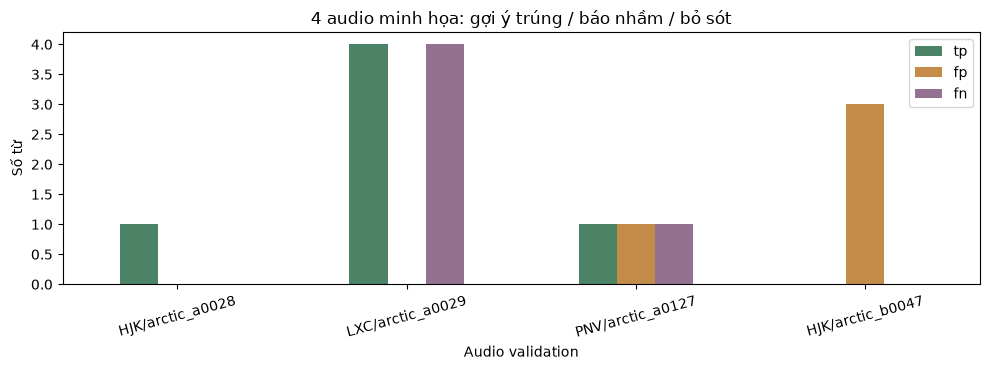

The fully correct control still has false alarms. No candidate is a claim of 100% correctness.


In [3]:
ax = checks.set_index('audio')[['tp','fp','fn']].plot.bar(
    figsize=(10,3.8), color=['#4c8265','#c38c49','#947190'])
ax.set_title('4 audio minh họa: gợi ý trúng / báo nhầm / bỏ sót')
ax.set_ylabel('Số từ'); ax.set_xlabel('Audio validation')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()
print('The fully correct control still has false alarms. No candidate is a claim of 100% correctness.')

## 2. Kiểm tra trên toàn bộ 450 validation

Đây là thống kê khác biệt âm theo từ điển và decoder, không phải điểm train mới hay calibration đã đạt.
Biến thể hợp lệ giảm một phần báo nhầm nhưng cũng bỏ sót thêm lỗi. PNV chỉ độc lập với bước chọn ngưỡng, từng được dùng chọn checkpoint B.

In [4]:
display(pd.DataFrame(report['validation_candidate_metrics']).T)
print('Exhaustive fit-only check:', report.get('exhaustive_fit_only'))
print('Official 900 test was not used to choose thresholds or run these checks.')

,tp,fp,tn,fn,unlabelled_words,precision,recall,false_positive_rate,fully_manual_correct_utterances,fully_manual_correct_utterances_with_candidates,candidate_flags_are_not_calibrated_decisions
all,1068,502,1929,623,117,0.680255,0.631579,0.206499,16,12,True
fit,628,413,1298,394,83,0.603266,0.614481,0.241379,16,12,True
heldout,440,89,631,229,34,0.831758,0.657698,0.123611,0,0,True


Exhaustive fit-only check: {'exploratory_only': True, 'heldout_used_to_select_thresholds': False, 'fit_labelled_words': 2733, 'distinct_eligible_fit_scores': 2185, 'feasible_partitions_under_unchanged_registered_criteria': 0, 'maximum_coverage_satisfying_rates_and_minimum_counts': {'coverage': 0.3505305525064032, 'tp': 168, 'fp': 74, 'tn': 674, 'fn': 42, 'accepted_score_groups': 716, 'rejected_tail_starts_after_group': 1943}, 'registered_policy': {'positive_class': 'manually annotated word has at least one substitution, deletion, or addition', 'max_false_positive_rate': 0.1, 'max_false_negative_rate': 0.2, 'min_coverage': 0.5, 'min_correct_decisions': 10, 'min_error_decisions': 5, 'grid_points': 31, 'objective': 'maximize labelled-word decision coverage subject to registered FPR/FRR and decision-count constraints; tie-break by decided F1'}, 'calibration_artifact_modified': False}
Official 900 test was not used to choose thresholds or run these checks.


### Gợi ý ngay theo ASR và sau khi sửa text

Replay dưới đây dùng posterior đã lưu của cùng 4 bản thu, không chạy lại model.
Cột ASR là gợi ý tạm tính xuất hiện ngay, không ép người dùng xác nhận trước.
`frout` không có tham chiếu từ điển nên không thể đoán rằng nó phải là `fraud`; khi sửa đúng từ thì mới có gợi ý âm tương ứng.
Bản thu đúng vẫn có báo nhầm: việc hiện gợi ý ngay không phải bằng chứng độ chính xác đã tăng.

In [5]:
replay = load(ROOT/'data/generated/optional-reference-qa/diagnostics.json')
display(pd.DataFrame([{'audio': item['utterance_id'],
                      'ASR': item['initial']['transcript'],
                      'initial_status': item['initial']['sound_candidates']['status'],
                      'initial_suggestions': ', '.join(w['text'] for w in item['initial']['sound_candidates']['words']),
                      'confirmed_text': item['confirmed']['reference_text'],
                      'confirmed_suggestions': ', '.join(w['text'] for w in item['confirmed']['sound_candidates']['words'])}
                     for item in replay['examples']]))

,audio,ASR,initial_status,initial_suggestions,confirmed_text,confirmed_suggestions
0,HJK/arctic_a0028,Robbery bribery frout,unavailable,,Robbery bribery fraud,fraud
1,LXC/arctic_a0029,Their forces were already moving into a north ...,available,"forces, were, north",Their forces were already moving into the nort...,"forces, were, the, north"
2,PNV/arctic_a0127,It was a temptation but he resisted it,available,"resisted, it",It was a temptation but he resisted it,"resisted, it"
3,HJK/arctic_b0047,Suppose you saw me at work through the window,available,"Suppose, through, the",Suppose you saw me at work through the window,"Suppose, through, the"


## 3. Lỗi bot chỉ nói Hi và các lượt Qwen thật

Lượt được báo lỗi thực sự có output backend `Hi!`, không phải trình duyệt cắt mất câu.
Các lượt Qwen dưới đây dùng transcript và history cố định, không giả làm kiểm thử nhận dạng audio.
Giữ nguyên cả các câu hỏi lại thông tin đã biết để thấy giới hạn của Qwen3-0.6B.

In [6]:
before = load(ROOT/'data/generated/chat-recovery-qa/reported-case.json')
print('Reported ASR:', before['asr_transcript'])
print('Reported reply:', before['text'])
conversation = load(ROOT/'data/generated/chat-recovery-qa/live-fewshot.json')
display(pd.DataFrame([{'case': case['label'], 'transcript_fixture': case['transcript_fixture'],
                      'actual_Qwen_reply': case['visible_output']} for case in conversation['cases']]))
print('Qualitative review:', conversation.get('qualitative_assessment'))
for limit in conversation.get('limitations', []): print('•', limit)

Reported ASR: It was the divicote true getesir
Reported reply: Hi!


,case,transcript_fixture,actual_Qwen_reply
0,work_specific_utterance,"I am a software developer, and I spend most of...",What's your main job or field?
1,work_follow_up_with_actual_previous_reply,The hardest part is understanding someone else...,What's the hardest part of your job?
2,reported_unclear_asr_phrase,It was the divicote true getesir,"Could you clarify what ""divicote"" refers to in..."


Qualitative review: {'overall': 'reported_hi_recovery_improved_general_context_still_weak', 'observations': 'The exact reported unclear ASR phrase now receives a real model-generated clarification with proper paired examples and the explicit clarification branch. Both work cases still repeat a question whose answer was supplied. Three sampled text fixtures are not a natural-conversation benchmark.'}
• This exercises real LocalSpeechEngine.run dialogue/guard/retry with explicitly stubbed acoustic and completion stages.
• Initial scenario history is a fixed test fixture; subsequent work turns use exact previous visible model/pipeline replies.
• The reported unclear-ASR phrase is exact, but the original recording/topic/history were not supplied to this probe.
• One stochastic response per case/attempt cannot establish conversational reliability.


## 4. Đối chiếu lại: thay câu bot, giữ bản thu

Kiểm thử web thật gửi audio local qua ASR + B + Qwen. Gợi ý âm xuất hiện ngay theo transcript ASR, chưa phải kết luận lỗi.
**Đối chiếu** chỉ sinh lại khi các từ thay đổi. Giữ nguyên từ hoặc chỉ sửa chữ hoa/dấu câu không xóa câu trả lời và voice.
Khi các từ thay đổi, bot xin lỗi một lần rồi trả lời tiếp theo text mới, cập nhật lịch sử cho lượt tiếp theo.
Transcript ASR gốc, audio và phoneme vẫn giữ nguyên. Chỉ Qwen chạy lại; không gọi lại ASR/B, không yêu cầu ai33/LLM API.
Gợi ý sửa ngữ pháp vẫn là tùy chọn, không tự thay câu tham chiếu.

In [7]:
REGEN = ROOT/'data/generated/optional-reference-qa'
pipeline = load(REGEN/'live-pipeline.json')
assert pipeline['status'] == 'passed' and not pipeline['training'] and not pipeline['paid_api_calls']
initial = pipeline['initial']
assert initial['speech']['sound_candidates']['provisional'] is True
rows = [{'revision': 0, 'conversation_text': initial['speech']['transcript'],
         'reply': initial['text'], 'candidate_words': '(awaiting confirmation)',
         'stages': ', '.join(pipeline['initial_stages'])}]
for revision, item in enumerate(pipeline['revisions'], 1):
    accepted, final = item['accepted'], item['final']
    assert accepted['text'] == '' and accepted['status'] == 'generating'
    assert final['id'] == initial['id'] and final['metadata']['reference_revision'] == revision
    assert final['speech']['transcript'] == initial['speech']['transcript']
    assert final['speech']['phonemes'] == initial['speech']['phonemes']
    assert not {'transcribing','analyzing'} & set(item['stages'])
    rows.append({'revision': revision, 'conversation_text': final['speech']['conversation_text'],
                 'reply': final['text'],
                 'candidate_words': ', '.join(w['text'] for w in final['speech']['sound_candidates']['words']),
                 'stages': ', '.join(item['stages'])})
display(pd.DataFrame(rows))
unchanged = pipeline['unchanged_checks']
for item in unchanged:
    assert item['response']['reference_update'] == {'changed': False, 'regenerated_reply': False}
display(pd.DataFrame([{'check': item['phase'], 'submitted_text': item['text'],
                      'reply_unchanged': True, 'revision': item['response']['metadata']['reference_revision']}
                     for item in unchanged]))
print('Initial provisional words:', [w['text'] for w in initial['speech']['sound_candidates']['words']])
for limit in pipeline.get('limits', []): print('•', limit)

,revision,conversation_text,reply,candidate_words,stages
0,0,Their forces were already moving into a north ...,Their forces were already moving into a north ...,(awaiting confirmation),"transcribing, generating, correcting, ready"
1,1,Their forces were already moving into the nort...,Sorry for the misunderstanding. That's a relief!,"forces, were, the, north","generating, correcting, ready"


,check,submitted_text,reply_unchanged,revision
0,initial_same_words,Their forces were already moving into a north ...,True,0
1,punctuation_and_case_only,THEIR FORCES WERE ALREADY MOVING INTO THE NORT...,True,1


Initial provisional words: ['forces', 'were', 'north']
• Conversation quality is not certified by this integration check.
• No ai33 request or physical speaker/microphone test was performed.


## 5. Lời xin lỗi, câu Qwen thật và giới hạn

Lời xin lỗi cố định do ứng dụng thêm, không ghi nhận thành đóng góp do model sinh.
Nội dung Qwen được kiểm tra lặp câu trước khi stream ra web/voice; câu lặp bị giữ lại, retry có giới hạn.
Đây là kiểm thử chức năng, chưa chứng minh hội thoại tự nhiên hay bộ lọc nhận biết mọi cách diễn đạt lại cùng ý.
Bảng lịch sử bên dưới giữ cả thất bại Qwen trong lượt kiểm tra trước khi thêm lời xin lỗi.

In [8]:
for item in pipeline['revisions']:
    final = item['final']
    print('Application apology:', final['metadata'].get('reference_apology'))
    print('Visible reply:', final['text'])
    display(pd.DataFrame(final['metadata']['reply_attempts']))
first_live = load(REGEN/'first-live-stock-praise.json')
print('First live run (preserved, off-topic phrasing praise):', first_live['revisions'][0]['final']['text'])
print('Passing the request/evidence checks does not certify a useful conversational answer.')
qwen = load(ROOT/'data/generated/reference-regeneration-qa/real-qwen.json')
display(pd.DataFrame([{'case': case['label'], 'visible_output': case['visible_output'],
                      'quality_review': case['qualitative_review']['status'],
                      'notes': case['qualitative_review']['notes']} for case in qwen['cases']]))
print('Actual model generations:', len(qwen['calls']))
print('Request/evidence checks:', qwen['review_summary']['request_evidence_checks_all_passed'])
print('Natural response failures:', qwen['review_summary']['natural_response_failed_cases'])
for limit in qwen['limitations']: print('•', limit)

Application apology: {'text': 'Sorry for the misunderstanding.', 'source': 'application'}
Visible reply: Sorry for the misunderstanding. That's a relief!


,raw_text,omitted_echoes,blocked_questions,finish_reason
0,Their forces were already moving into the nort...,[Their forces were already moving into the nor...,[],stop
1,That's a relief!,[],[],stop


First live run (preserved, off-topic phrasing praise): Sorry for the misunderstanding. That's a good way to say it.
Passing the request/evidence checks does not certify a useful conversational answer.


,case,visible_output,quality_review,notes
0,corrected_reported_phrase,I'm having trouble continuing this conversatio...,failed_model_relevance,Both actual Qwen attempts repeated the confirm...
1,confirmed_cafe_order,What temperature would you like for your coffe...,passed_narrow_context_check,Actual Qwen asks for a missing temperature pre...
2,human_confirmed_ambiguous_phrase,What was the blue thing there yesterday?,passed_narrow_clarification_check,Actual Qwen asks what the blue thing was witho...


Actual model generations: 6
Request/evidence checks: True
Natural response failures: ['corrected_reported_phrase']
• Speech/assessment snapshots and pre-turn histories are fixtures, not an acoustic benchmark.
• One stochastic response per case cannot establish natural conversation reliability.
• Qualitative relevance must be reviewed separately from request/evidence invariants.


## 6. Kiểm tra giao diện và lệnh chạy lại

Browser test dùng job/voice giả lập để kiểm tra stream, đổi revision, lịch sử, hủy và chặn voice cũ.
Kiểm tra thêm gợi ý âm xuất hiện ngay, text không đổi giữ câu cũ, và mở collapse/người dùng cuộn lên không bị kéo xuống khi stream/highlight.
Đây là kiểm thử tích hợp giao diện, không phải đánh giá chất lượng model hay nghe loa thực tế.
Từ chưa có trong từ điển vẫn dùng được cho hội thoại; phần âm báo rõ chưa có tham chiếu, không gọi là đúng.

In [9]:
browser = load(REGEN/'browser-summary.json')
assert browser['status'] == 'passed' and not browser['exceptions']
display(pd.DataFrame({'browser_check': browser['checks']}))
print('Physical audio limitation:', browser['speech'])
print('Replay commands (not executed):')
print(f'"{sys.executable}" scripts/check_pronunciation_error_examples.py --real-audio')
print(f'"{sys.executable}" scripts/check_reference_regeneration_live.py')
print('node scripts/check_reference_regeneration_browser.cjs')
print('Local audio report:', OUT/'report.html')

,browser_check
0,"Case, punctuation and spacing changes confirm ..."
1,"Confirm immediately clears the old bot reply, ..."
2,"Streaming text, native word highlighting and p..."
3,Same-job streamed regeneration ignores stale r...
4,Repeating an already confirmed sentence is a s...
5,The next conversation request uses the confirm...
6,"A rejected POST restores the previous reply, p..."
7,A backend-declared no-op is accepted independe...
8,Cancel during regeneration stops that same job...
9,An unchanged reading prompt takes precedence o...


Physical audio limitation: simulated speech boundaries and audio; physical audio not tested
Replay commands (not executed):
"D:\NCC\MDD\.venv\Scripts\python.exe" scripts/check_pronunciation_error_examples.py --real-audio
"D:\NCC\MDD\.venv\Scripts\python.exe" scripts/check_reference_regeneration_live.py
node scripts/check_reference_regeneration_browser.cjs
Local audio report: D:\NCC\MDD\data\generated\pronunciation-error-qa\report.html


## 7. Ngữ pháp: sửa wakes → wake nhưng bộ lọc từng loại mất kết quả

Ba câu phát triển được thử bằng **Qwen3-0.6B base thật**, cùng prompt và greedy decoding trước/sau.
Model đã sửa lỗi ở câu người dùng cung cấp; bộ lọc cũ lại loại vì lược đại từ lặp sau `then` hoặc đổi `am` thành `a.m.`.
Thay đổi nằm ở bộ lọc và hiển thị từng đề xuất độc lập, không train hoặc đổi trọng số/prompt.
Đây là regression có chủ đích, không phải benchmark ngữ pháp trên dữ liệu chưa thấy.

In [10]:
GRAMMAR = ROOT/'data/generated/grammar-routine-qa'
before_writing, after_writing = load(GRAMMAR/'before.json'), load(GRAMMAR/'after.json')
comparison_writing = load(GRAMMAR/'comparison.json')
old_by_label = {item['label']: item for item in before_writing['cases']}
writing_rows = []
for item in after_writing['cases']:
    previous = old_by_label[item['label']]
    assert item['request'] == previous['request']
    parsed = item['parsed']
    writing_rows.append({'case': item['label'], 'input': item['transcript'],
                         'before_parser': previous['parsed']['status'], 'after_parser': parsed['status'],
                         'grammar': parsed.get('grammar_corrected'), 'natural': parsed.get('natural'),
                         'edits': parsed.get('explanation')})
writing_table = pd.DataFrame(writing_rows)
display(writing_table)
print('Causal check:', comparison_writing['method'])
print('Fresh structured calls before / after:', before_writing['actual_generations'], after_writing['actual_generations'])
for limit in after_writing['limitations']: print('•', limit)

,case,input,before_parser,after_parser,grammar,natural,edits
0,exact_user_routine,i usually wakes up at seven am then i brush my...,unavailable,ready,"I usually wake up at seven am, then brush my t...","I usually wake up at seven am, then brush my t...",wakes → wake · Omit “i”
1,already_correct_routine,"I usually wake up at seven am, then I brush my...",ready,ready,"I usually wake up at seven am, then I brush my...","I usually wake up at seven am, then I brush my...",No wording change was suggested.
2,negation_preservation,"I do not usually wake up at seven am, and I do...",unavailable,ready,"I do not usually wake up at seven a.m., and I ...","I don't usually wake up at seven a.m., and I d...",do not → don't · do not → don't


Causal check: Reparse the exact genuine BEFORE raw model outputs using the new parser. No new model calls in this comparison.
Fresh structured calls before / after: 3 3
• One greedy structured generation per supplied sentence; no audio, conversation reply, or grammar benchmark.
• The raw model JSON and conservative lexical parser are evaluated separately.
• The exact reported case is a development regression, not an unseen held-out test.


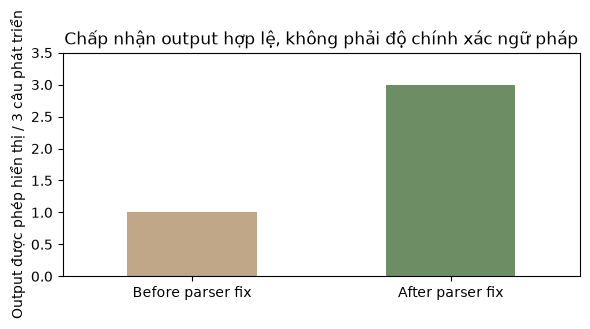

In [11]:
accepted = pd.Series({'Before parser fix': sum(row['before_parser'] == 'ready' for row in writing_rows),
                      'After parser fix': sum(row['after_parser'] == 'ready' for row in writing_rows)})
ax = accepted.plot.bar(figsize=(6,3), color=['#bfa787','#6d8d64'], rot=0)
ax.set_ylim(0, len(writing_rows) + .5)
ax.set_ylabel('Output được phép hiển thị / 3 câu phát triển')
ax.set_title('Chấp nhận output hợp lệ, không phải độ chính xác ngữ pháp')
plt.tight_layout(); plt.show()

## 8. Câu nhiều lỗi và thứ tự collapse → bot trả lời

Câu `Yesterday I wake up at 7, I no brush teeth...` được thử trước/sau với Qwen thật.
Bộ lọc mới hỗ trợ các nhóm chỉnh sửa ngữ pháp có giới hạn: động từ bất quy tắc, phủ định của người học,
khôi phục cùng chủ thể và từ chức năng tại một số cấu trúc. Chủ thể khác, sở hữu có sẵn, giờ và phủ định vẫn được bảo vệ.
Đây là đề xuất viết lại, không thay bản thu, transcript, lịch sử hoặc tham chiếu phát âm.

**Giới hạn thực tế:** prompt mới yêu cầu sửa câu nối bằng dấu phẩy, nhưng Qwen0.6B vẫn giữ comma splice ở ví dụ này.
Output khả dụng không có nghĩa đã sửa ngữ pháp hoàn hảo. Không chọn lại lượt sinh để che lỗi.

In [12]:
PAST = ROOT/'data/generated/grammar-past-qa'
past_before, past_after = load(PAST/'before.json'), load(PAST/'after.json')
old_past = {item['label']: item for item in past_before['cases']}
display(pd.DataFrame([{'case': item['label'], 'input': item['transcript'],
                      'before': old_past[item['label']]['parsed']['status'],
                      'after': item.get('final_parsed', item['parsed'])['status'],
                      'grammar': item.get('final_parsed', item['parsed'])['grammar_corrected'],
                      'natural': item.get('final_parsed', item['parsed'])['natural']}
                     for item in past_after['cases']]))
print('Actual calls before / after:', past_before['actual_generations'], past_after['actual_generations'])
print('The model still leaves comma splices in the reported example; these are draft suggestions.')

,case,input,before,after,grammar,natural
0,exact_user_past,"Yesterday I wake up at 7, I no brush teeth and...",unavailable,ready,"Yesterday I woke up at 7, I didn't brush my te...","Yesterday I woke up at 7, I didn't brush my te..."
1,correct_past_negation_control,Yesterday I woke up at 7. I did not brush my t...,ready,ready,"Yesterday, I woke up at 7. I did not brush my ...","Yesterday, I woke up at 7. I did not brush my ..."


Actual calls before / after: 2 2
The model still leaves comma splices in the reported example; these are draft suggestions.


In [13]:
order = load(PAST/'live-order.json')
assert order['status'] == 'passed'
timing = order['feedback_first']
assert timing['feedback_ready_sec'] <= timing['first_text_sec']
display(pd.DataFrame([{'observed_event': 'Collapse feedback ready', 'seconds': timing['feedback_ready_sec']},
                      {'observed_event': 'First bot text', 'seconds': timing['first_text_sec']}]))
print('Checks use one real local audio; polling timing is approximate. No TTS was requested.')
print('Replay command (not executed):')
print(f'"{sys.executable}" scripts/check_reference_regeneration_live.py --feedback-first-only '
      '--output data/generated/grammar-past-qa/live-order.json')

,observed_event,seconds
0,Collapse feedback ready,22.235
1,First bot text,26.047


Checks use one real local audio; polling timing is approximate. No TTS was requested.
Replay command (not executed):
"D:\NCC\MDD\.venv\Scripts\python.exe" scripts/check_reference_regeneration_live.py --feedback-first-only --output data/generated/grammar-past-qa/live-order.json
